# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
# TODO: read PATIENTS_PATH with pd.read_csv

patients = pd.read_csv(PATIENTS_PATH)

# TODO: print the shape and the dtypes of patients
print(patients.shape)
print(patients.dtypes)

# TODO: the Altair scatter plot README Task 1.1 describes
exploratory_chart = (
    alt.Chart(patients)
    .mark_point(
        filled=True,
        size=90
    )
    .encode(
        x=alt.X(
            "sessions_attended:Q",
            title="Sessions attended (of 36)"
        ),
        y=alt.Y(
            "walk_distance_m:Q",
            title="Six-minute walk distance (m)",
            scale=alt.Scale(zero=False)
        ),
        color=alt.Color(
            "program:N",
            title="Program",
            scale=alt.Scale(
                range=[BLUE, ORANGE]
            )
        ),
        shape=alt.Shape(
            "program:N",
            title="Program"
        ),
        tooltip=[
            alt.Tooltip("patient_id:N", title="Patient ID"),
            alt.Tooltip("program:N", title="Program"),
            alt.Tooltip("sessions_attended:Q", title="Sessions attended"),
            alt.Tooltip("walk_distance_m:Q", title="Walk distance (m)")
        ]
    )
    .properties(
        title="Rehabilitation attendance and walking distance"
    )
)

exploratory_chart.show()

# TODO: save exploratory_chart to EXPLORATORY_SPEC_PATH with .save()
exploratory_chart.save(EXPLORATORY_SPEC_PATH)

(12, 4)
patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object


alt.Chart(...)

### 1.2 Describe what the chart shows

This chart explores whether patients who attended more rehabilitation sessions tended to have a longer six-minute walk distance, and whether that pattern differed between the home-based and center-based programs. Each point represents one patient, with sessions attended on the x-axis and walking distance on the y-axis; color and shape indicate different rehabilitation programs. The points show a positive association between the number of sessions attended and six-minute walk distance. Though association exist, we cannot yet conclude to a causation because we do not know the baseline characteristics of these patients, therefore cannot claim that they are exchangeable. Also the sample size of 12 is way too small.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


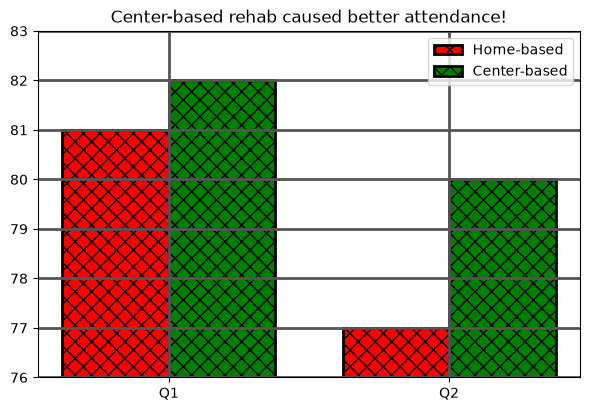

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim", 
        "problem": "The title says that center-based rehab caused better attendance, but the chart only compares attendance percentages and does not establish causation.", 
        "repair": "Use a descriptive title 'Rehabilitation attendance by program and quarter'."},  
    {"category": "truncated baseline", 
        "problem": "The y-axis starts near 76%, which visually exaggerates the small differences in attendance between programs.", 
        "repair": "Start the bar-chart y-axis at 0% with ax.set_ylim(0, 100)."},
    {"category": "missing unit", 
        "problem": "The y-axis has no label, so readers may confuse the values with percentages or raw counts.", 
        "repair": "Label the y-axis 'Attendance (%)'."},
    {"category": "color-only encoding", 
        "problem": "Only red versus green separates the seasons, and the bars use the same hatch pattern; colorblind readers may not be able to tell them apart.", 
        "repair": "'Use colorblind-safe colors plus a different hatch or direct label for each program."},
    {"category": "distracting decoration", 
        "problem": "Thick black edges, a heavy grid, and the same hatch on every bar carry no data.", 
        "repair": "Drop the edges and grid and keep hatches only where they mark the season."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title says that center-based rehab caused better attendance, but the chart only compares attendance percentages and does not establish causation.
    repair: Use a descriptive title 'Rehabilitation attendance by program and quarter'.
truncated baseline: The y-axis starts near 76%, which visually exaggerates the small differences in attendance between programs.
    repair: Start the bar-chart y-axis at 0% with ax.set_ylim(0, 100).
missing unit: The y-axis has no label, so readers may confuse the values with percentages or raw counts.
    repair: Label the y-axis 'Attendance (%)'.
color-only encoding: Only red versus green separates the seasons, and the bars use the same hatch pattern; colorblind readers may not be able to tell them apart.
    repair: 'Use colorblind-safe colors plus a different hatch or direct label for each program.
distracting decoration: Thick black edges, a heavy grid, and the same hatch on every bar carry no data.
    repair: Drop the edges a

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

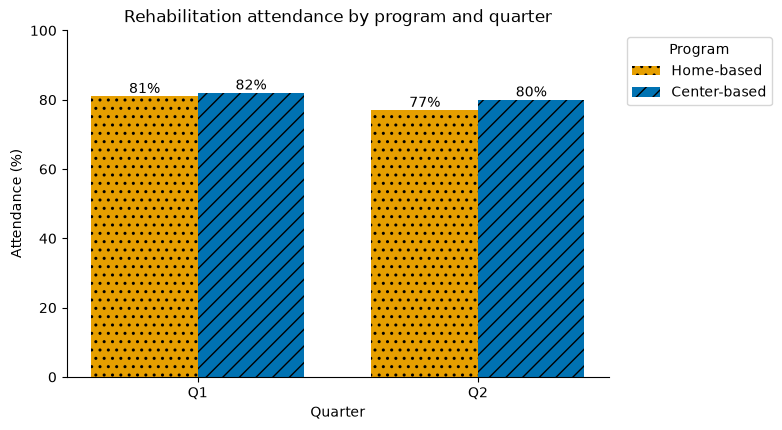

y-axis runs from 0.0 to 100.0


In [7]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

# TODO: draw the four bars again from home and center on redesign_ax, repairing each problem in your critique
# (README Task 2.3 lists the repairs)
# Draw the same four bars, but repair the visual problems
home_bars = redesign_ax.bar(
    x - width / 2,
    home,
    width,
    label="Home-based",
    color=ORANGE,
    hatch=".."
)

center_bars = redesign_ax.bar(
    x + width / 2,
    center,
    width,
    label="Center-based",
    color=BLUE,
    hatch="//"
)

# Correct baseline
redesign_ax.set_ylim(0, 100)

# Axis labels and units
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Attendance (%)")

# Quarter labels
redesign_ax.set_xticks(x, quarters)

# Put values directly on the bars
redesign_ax.bar_label(home_bars, fmt="%d%%")
redesign_ax.bar_label(center_bars, fmt="%d%%")

# Descriptive, non-causal title
redesign_ax.set_title("Rehabilitation attendance by program and quarter")

# Remove unnecessary decoration
redesign_ax.spines["top"].set_visible(False)
redesign_ax.spines["right"].set_visible(False)

# Legend outside the plotting area
redesign_ax.legend(
    title="Program",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

# TODO: save redesign_fig to REDESIGN_PATH with dpi=150 and bbox_inches="tight"
redesign_fig.savefig(
    REDESIGN_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
# TODO: read FOLLOWUP_PATH with pd.read_csv
followup = pd.read_csv(FOLLOWUP_PATH)  
# TODO: display followup
display(followup)

question = ""  # TODO: the comparison the chart should help the coordinator make
audience = ""  # TODO: who reads the chart and what they will use it for
intended_claim = ""  # TODO: the one descriptive conclusion the chart supports
y_measure = ""  # TODO: what the y-axis measures, with its unit
grain = ""  # TODO: what one row of the plotting table and one point on a line represent
data_types = {
    "program": "",  # TODO: categorical, quantitative, ordinal, or temporal
    "visit_number": "",  # TODO
    "goal_met_pct": "",  # TODO
}

supporting_data = None  # TODO: the three plotted columns of followup

# TODO: save supporting_data to SUPPORTING_DATA_PATH without the row index

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


FileNotFoundError: [Errno 2] No such file or directory: 'output/explanatory_supporting_data.csv'

### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

In [ ]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

# TODO: draw one line per program on explanatory_ax, with visit_number on x and goal_met_pct on y,
# and finish the chart as README Task 3.2 describes

# TODO: save explanatory_fig to EXPLANATORY_PATH with dpi=150 and bbox_inches="tight"

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [ ]:
text_alternative = ""  # TODO: one paragraph, as README Task 3.3 describes

visualization_evidence = {
    "critique": critique,
    # TODO: add question, audience, intended_claim, y_measure, grain, data_types, and text_alternative
}

# TODO: save visualization_evidence to EVIDENCE_PATH with json.dump, as the Task 2.2 cell does

# TODO: write text_alternative to TEXT_ALTERNATIVE_PATH

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

TODO: Replace this line with your answers.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [ ]:
from check_assignment import run_checks

_ = run_checks()